            Page_Views  Unique_Visitors  Bounce_Rate
Date                                                
2025-01-01         508              305    40.688935
2025-01-02         523              314    57.204853
2025-01-03         502              291    38.163967
2025-01-04         490              318    49.430704
2025-01-05         520              297    30.015611


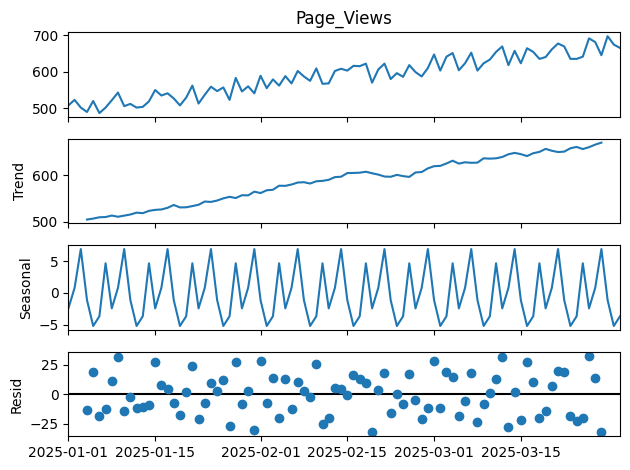

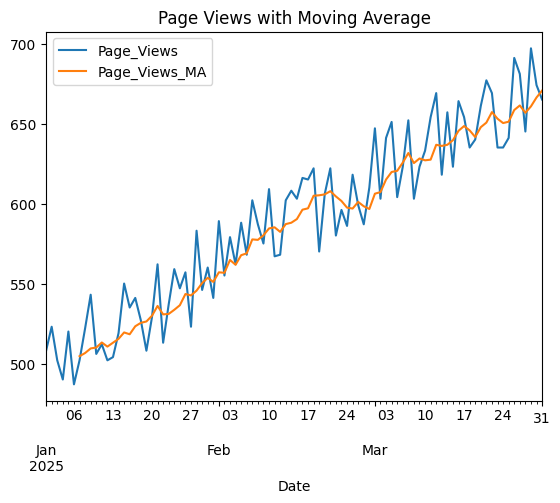

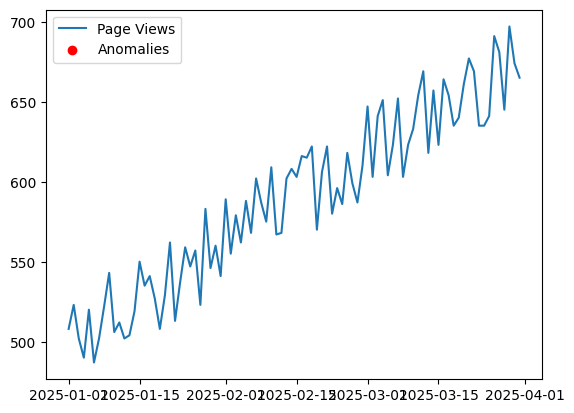

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose

dates = pd.date_range(start='2025-01-01', periods=90, freq='D')
np.random.seed(42)

data = pd.DataFrame({
    'Date': dates,
    'Page_Views': 500 + np.arange(90) * 2 + np.random.randint(-30, 30, 90),
    'Unique_Visitors': 300 + np.arange(90) + np.random.randint(-20, 20, 90),
    'Bounce_Rate': np.random.uniform(30, 60, 90)
})

data.set_index('Date', inplace=True)

print(data.head())

data['Page_Views'] = data['Page_Views'].interpolate()

decomposition = seasonal_decompose(data['Page_Views'], model='additive', period=7)
decomposition.plot()
plt.show()

data['Page_Views_MA'] = data['Page_Views'].rolling(window=7).mean()
data[['Page_Views', 'Page_Views_MA']].plot()
plt.title('Page Views with Moving Average')
plt.show()

data['Page_Views_Z'] = (
    (data['Page_Views'] - data['Page_Views'].mean())
    / data['Page_Views'].std()
)

anomalies = data[data['Page_Views_Z'].abs() > 2]

plt.plot(data.index, data['Page_Views'], label='Page Views')
plt.scatter(anomalies.index, anomalies['Page_Views'], color='red', label='Anomalies')
plt.legend()
plt.show()